# Part A · Nine charts, rebuilt and taken apart

**Ali Afzal** · BSAI-7B-102 · Data Visualization · Week 3

Nine analysts published nine claims. For each one I follow their recipe, check the self-check number,
and then ask four questions: what does the chart invite me to conclude, what objection comes to mind
first (and why it doesn't hold), what is really producing the pattern, and what does the honest chart
look like.

"Correlation is not causation" names no mechanism, so it never counts as an answer here. Each mechanism
below is a named third variable, a named drawing decision or a named arithmetic fact, with the number
that proves it.

Every figure puts the published chart on the left (**AS PUBLISHED**) and my redesign on the right.

In [1]:
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import gaussian_kde, norm

from vizlib import MARKERS, PALETTE, save_fig, style_defaults

DATA = Path("data")
CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)
style_defaults(dpi=100)
BLUE, ORANGE, GREEN = PALETTE["series"]
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]
SOURCE = "Source: synthetic course data, CDB601220 Week 3."


def wrap(text, width=55):
    return textwrap.fill(text, width)


def published(ax, claim):
    ax.set_title(wrap(f"AS PUBLISHED: “{claim}”", 60), fontsize=10, color=SOFT)


def save(fig, name, note=""):
    save_fig(fig, CHARTS / name, note=f"{note}  {SOURCE}".strip())


def summary_table(df, key, x, y):
    rows = {}
    for k, g in df.groupby(key):
        rows[k] = {"n": len(g), f"mean {x}": g[x].mean(), f"mean {y}": g[y].mean(),
                   f"SD {x}": g[x].std(), f"SD {y}": g[y].std(),
                   "Pearson r": g[x].corr(g[y]), "slope": np.polyfit(g[x], g[y], 1)[0]}
    return pd.DataFrame(rows).round(3)

---
## 1 · "Premium-certified helmets have 2.5x the head-injury rate"

Recipe: sum `head_injuries` and `trips` by `helmet_grade`, and plot injuries per 1,000 trips as bars from zero.

In [2]:
c1 = pd.read_csv(DATA / "case01_helmet_rickshaw.csv")
by_grade = c1.groupby("helmet_grade")[["head_injuries", "trips"]].sum()
by_grade["per_1000"] = by_grade.head_injuries / by_grade.trips * 1000
by_grade.round(2)

,head_injuries,trips,per_1000
helmet_grade,,,
Premium,216,40000,5.40
Standard,129,60000,2.15


**Self-check:** Standard 2.15, Premium 5.40. ✓

**The conclusion it invites.** Premium helmets make head injuries more likely, so stop buying them.

**The decoy.** "Premium riders feel safer and ride faster" (risk compensation). The file has
`avg_speed_kph`, so I can test it. Within each road type, Premium and Standard riders travel at almost
the same speed (motorway 72.2 vs 71.0 km/h, city 39.6 vs 38.0, lanes 25.6 vs 24.0). Rider behaviour
isn't the difference.

In [3]:
by_road = c1.groupby(["road_type", "helmet_grade"])[["head_injuries", "trips", "avg_speed_kph"]].agg(
    {"head_injuries": "sum", "trips": "sum", "avg_speed_kph": "mean"})
by_road["per_1000"] = by_road.head_injuries / by_road.trips * 1000
mix = c1.groupby(["helmet_grade", "road_type"]).trips.sum().unstack()
print(by_road.round(2))
print("\nshare of each grade's trips by road type (%):")
print((mix.div(mix.sum(axis=1), axis=0) * 100).round(1))

                               head_injuries  trips  avg_speed_kph  per_1000
road_type        helmet_grade                                               
City arterial    Premium                  11   5000          39.61      2.20
                 Standard                 60  20000          38.02      3.00
Inner-city lanes Premium                   1   1000          25.55      1.00
                 Standard                 53  38000          23.98      1.39
Motorway         Premium                 204  34000          72.19      6.00
                 Standard                 16   2000          70.95      8.00

share of each grade's trips by road type (%):
road_type     City arterial  Inner-city lanes  Motorway
helmet_grade                                           
Premium                12.5               2.5      85.0
Standard               33.3              63.3       3.3


**The mechanism: Simpson's paradox, with road type as the confounder.** On **every** road type, Premium
has the *lower* injury rate: motorway 6.0 vs 8.0, city arterial 2.2 vs 3.0, inner-city lanes 1.0 vs 1.4.
But **85% of Premium trips are on motorways**, the most dangerous roads, against 3.3% of Standard trips.
Premium helmets are issued to the riders who face the most danger, and pooling the road types hides that
exposure mix. The pooled bar compares motorways with side streets, not one helmet with another.

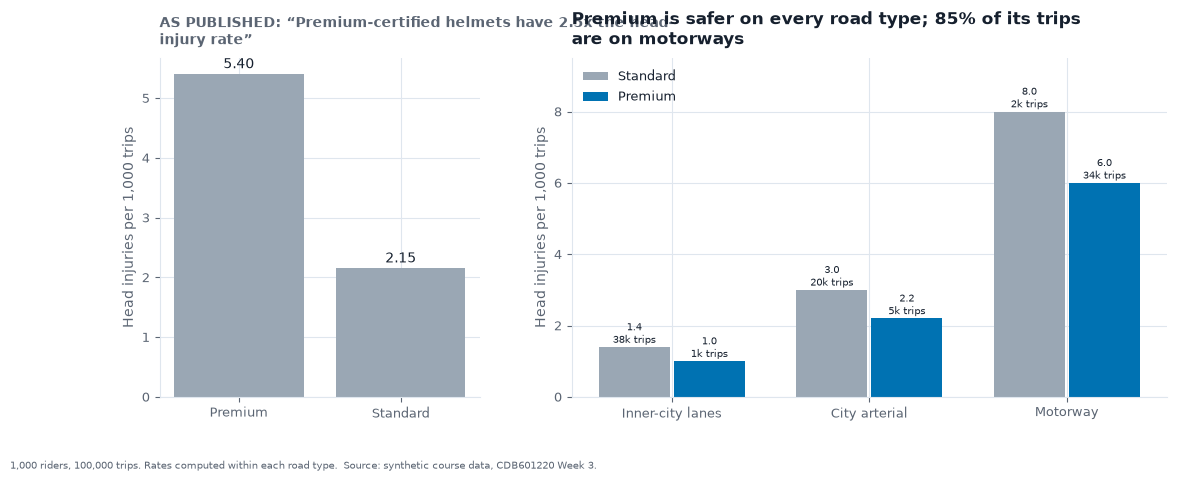

In [4]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw=dict(width_ratios=[0.7, 1.3]))
a.bar(by_grade.index, by_grade.per_1000, color=GREY)
for i, v in enumerate(by_grade.per_1000):
    a.text(i, v + 0.1, f"{v:.2f}", ha="center")
a.set_ylabel("Head injuries per 1,000 trips")
published(a, "Premium-certified helmets have 2.5x the head-injury rate")

roads = ["Inner-city lanes", "City arterial", "Motorway"]
x = np.arange(len(roads))
for k, (grade, col) in enumerate([("Standard", GREY), ("Premium", BLUE)]):
    vals = [by_road.loc[(r, grade), "per_1000"] for r in roads]
    trips = [by_road.loc[(r, grade), "trips"] for r in roads]
    b.bar(x + (k - 0.5) * 0.38, vals, width=0.36, color=col, label=grade)
    for xi, v, t in zip(x, vals, trips):
        b.text(xi + (k - 0.5) * 0.38, v + 0.12, f"{v:.1f}\n{t / 1000:.0f}k trips", ha="center", fontsize=7.5)
b.set_xticks(x, roads)
b.set_ylim(0, 9.5)
b.set_ylabel("Head injuries per 1,000 trips")
b.legend(loc="upper left")
b.set_title(wrap("Premium is safer on every road type; 85% of its trips are on motorways"))
save(fig, "a1_simpson_helmets.png", "1,000 riders, 100,000 trips. Rates computed within each road type.")

**The redesign.** The same bars, split by road type, with the number of trips under each bar so the
exposure mix can be seen. Premium is lower in all three pairs.

---
## 2 · "Canteen chai sales predict quiz failures"

Recipe: scatter cups sold against quiz failures, one point per month, a least-squares line, Pearson r.

In [5]:
c2 = pd.read_csv(DATA / "case02_chai_quizzes.csv")
r2 = c2.cups_doodh_patti_sold.corr(c2.quiz_failures)
print(f"r = {r2:.2f} across {len(c2)} months")
print(c2.drop(columns="month").corr().round(3)[["cups_doodh_patti_sold", "quiz_failures"]])

r = 0.98 across 24 months
                       cups_doodh_patti_sold  quiz_failures
students_enrolled                      0.997          0.977
cups_doodh_patti_sold                  1.000          0.982
quiz_failures                          0.982          1.000
is_exam_month                          0.058          0.211
campus_open_days                       0.153          0.225


**Self-check:** r = 0.98. ✓

**The conclusion it invites.** Chai is bad for grades, or at least chai sales warn of failures.

**The decoy.** "Exam months drive both: students drink more chai and fail more quizzes at exam time."
Testable, since `is_exam_month` is in the file. Within the 16 non-exam months alone r is still **0.996**,
and within the 8 exam months it is also **0.996**. Exam timing isn't what produces it.

In [6]:
for m, g in c2.groupby("is_exam_month"):
    print(f"is_exam_month={m}: {len(g):2d} months, r(cups, failures) = {g.cups_doodh_patti_sold.corr(g.quiz_failures):.3f}")
c2["cups_per_student"] = c2.cups_doodh_patti_sold / c2.students_enrolled
c2["failures_per_100"] = c2.quiz_failures / c2.students_enrolled * 100
r_pc = c2.cups_per_student.corr(c2.failures_per_100)
print(f"enrolment grew {c2.students_enrolled.iloc[0]:,} -> {c2.students_enrolled.iloc[-1]:,} "
      f"({c2.students_enrolled.iloc[-1] / c2.students_enrolled.iloc[0] - 1:+.0%})")
print(f"per student: r(cups per student, failures per 100 students) = {r_pc:.2f}")

is_exam_month=0: 16 months, r(cups, failures) = 0.996
is_exam_month=1:  8 months, r(cups, failures) = 0.996
enrolment grew 1,765 -> 5,406 (+206%)
per student: r(cups per student, failures per 100 students) = 0.29


**The mechanism: enrolment is the third variable.** Both columns are counts of things students do, and
the number of students rose over the 24 months. r(enrolment, cups) = **0.997** and r(enrolment, failures)
= **0.977**: more students, more chai, more failures. Divide both by enrolment and the correlation drops
from 0.98 to **0.29**. Even that is driven mostly by exam months, which raise both rates.

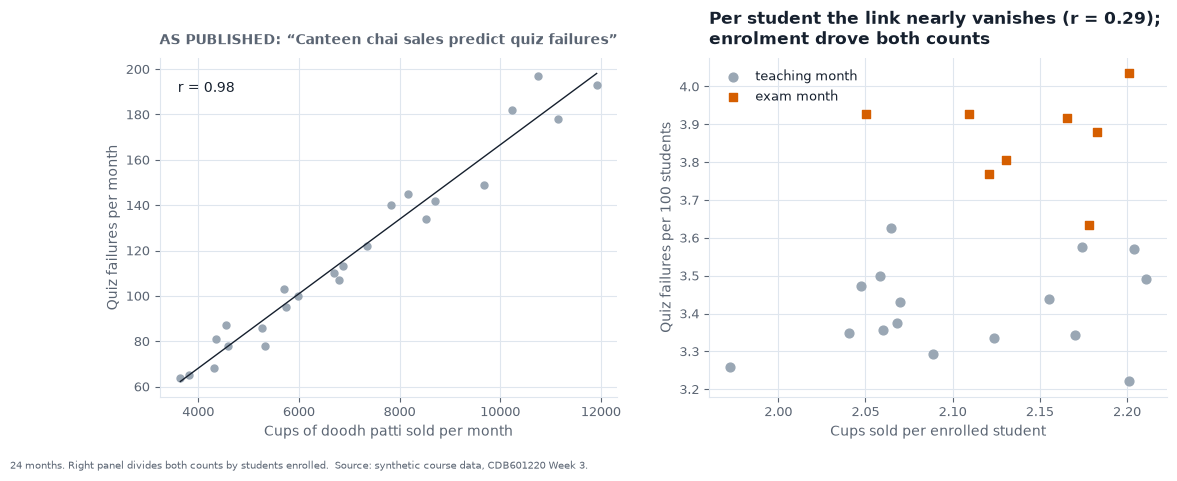

In [7]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.4))
a.scatter(c2.cups_doodh_patti_sold, c2.quiz_failures, color=GREY)
p = np.polyfit(c2.cups_doodh_patti_sold, c2.quiz_failures, 1)
xs = np.linspace(c2.cups_doodh_patti_sold.min(), c2.cups_doodh_patti_sold.max(), 2)
a.plot(xs, np.polyval(p, xs), color=INK, lw=1)
a.text(0.04, 0.9, f"r = {r2:.2f}", transform=a.transAxes)
a.set_xlabel("Cups of doodh patti sold per month")
a.set_ylabel("Quiz failures per month")
published(a, "Canteen chai sales predict quiz failures")

for m, (col, mk, lab) in enumerate([(GREY, "o", "teaching month"), (ORANGE, "s", "exam month")]):
    g = c2[c2.is_exam_month == m]
    b.scatter(g.cups_per_student, g.failures_per_100, color=col, marker=mk, s=40, label=lab)
b.set_xlabel("Cups sold per enrolled student")
b.set_ylabel("Quiz failures per 100 students")
b.legend(loc="upper left")
b.set_title(wrap(f"Per student the link nearly vanishes (r = {r_pc:.2f}); enrolment drove both counts"))
save(fig, "a2_chai_enrolment.png", "24 months. Right panel divides both counts by students enrolled.")

**The redesign.** Plot rates per student instead of raw counts, and mark exam months with colour *and*
shape. What's left is weak, and it's about exams, not chai.

---
## 3 · "The Smog Action Plan cut Lahore's AQI by a third"

Recipe: mean AQI per date across every row, a line with the y-axis from zero, a marker at day 61 and two
period means.

In [8]:
c3 = pd.read_csv(DATA / "case03_aqi_monitors.csv", parse_dates=["date"])
c3["day"] = (c3.date - c3.date.min()).dt.days + 1
daily = c3.groupby("day").aqi.mean()
before, after = daily[daily.index <= 60].mean(), daily[daily.index > 60].mean()
print(f"before {before:.0f}, after {after:.0f}, change {after / before - 1:+.0%}")

before 202, after 137, change -32%


**Self-check:** before 202, after 137, a 32% fall. ✓

**The conclusion it invites.** The plan worked: the air got a third cleaner on day 61.

**The decoy.** "The y-axis is truncated." It isn't. The recipe starts it at zero, and so does my code.
The 32% is real arithmetic on the numbers drawn.

In [9]:
status = c3.assign(period=np.where(c3.day <= 60, "days 1-60", "days 61-120")).groupby(
    ["zone", "period"]).aqi.agg(stations_reporting=lambda s: s.notna().groupby(c3.loc[s.index, "station_id"]).any().sum(),
                                mean_aqi="mean").unstack().round(1)
print(status)
st = c3.groupby(["station_id", c3.day > 60]).aqi.mean().unstack()
both = st.dropna()
print(f"\nstations reporting in both periods: {len(both)}; their mean AQI {both[False].mean():.1f} -> {both[True].mean():.1f}")

            stations_reporting              mean_aqi            
period               days 1-60 days 61-120 days 1-60 days 61-120
zone                                                            
Arterial                     6           3     244.7       245.9
Industrial                   6           0     322.0         NaN
Peri-urban                   4           4      78.9        80.4
Residential                  6           6     121.6       120.8

stations reporting in both periods: 13; their mean AQI 137.1 -> 137.2


**The mechanism: the network changed, not the air.** On day 61, **nine stations stopped reporting**: all
six Industrial stations (mean AQI 322) and three of the six Arterial ones (245). `mean()` skips blanks
without warning, so after day 61 the city "average" is an average of the cleaner residential and
peri-urban stations. The 13 stations that reported throughout went from **137.1 to 137.2**. Every zone's
own mean is flat across day 61. The 32% fall comes entirely from losing the dirtiest monitors.

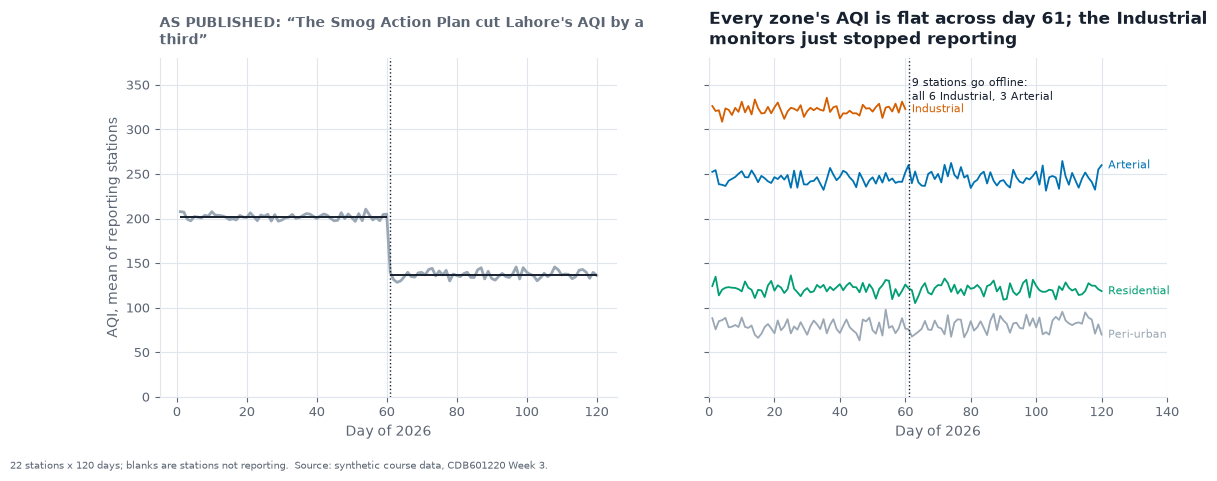

In [10]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
a.plot(daily.index, daily.values, color=GREY)
a.axvline(61, color=INK, ls=":", lw=1)
a.hlines([before, after], [1, 61], [60, 120], color=INK, lw=1.4)
a.set_ylim(0, 380)
a.set_xlabel("Day of 2026")
a.set_ylabel("AQI, mean of reporting stations")
published(a, "The Smog Action Plan cut Lahore's AQI by a third")

zone_daily = c3.groupby(["day", "zone"]).aqi.mean().unstack()
zcol = {"Industrial": ORANGE, "Arterial": BLUE, "Residential": GREEN, "Peri-urban": GREY}
for z in ["Industrial", "Arterial", "Residential", "Peri-urban"]:
    b.plot(zone_daily.index, zone_daily[z], color=zcol[z], lw=1.3)
    last = zone_daily[z].dropna()
    b.text(last.index[-1] + 2, last.iloc[-1], z, va="center", fontsize=8, color=zcol[z])
b.axvline(61, color=INK, ls=":", lw=1)
b.text(62, 360, "9 stations go offline:\nall 6 Industrial, 3 Arterial", fontsize=8, va="top")
b.set_xlim(0, 140)
b.set_xlabel("Day of 2026")
b.set_title(wrap("Every zone's AQI is flat across day 61; the Industrial monitors just stopped reporting"))
save(fig, "a3_aqi_stations_offline.png", "22 stations x 120 days; blanks are stations not reporting.")

**The redesign.** One line per zone, and the Industrial line simply *stops*. A city-wide mean is only
comparable over time if the same stations feed it. The honest headline uses the 13 constant stations:
no change.

---
## 4 · "Four departments behave identically, so fund them equally"

Recipe: not a chart, just a table of n, means, SDs, r and slope per department.

In [11]:
c4 = pd.read_csv(DATA / "case04_quartet_depts.csv")
summary_table(c4, "department", "study_hours_per_week", "final_score_out_of_20")

,Architecture,Business Administration,Computer Science,Electrical Engineering
n,11.000,11.000,11.000,11.000
mean study_hours_per_week,18.000,18.000,18.000,18.000
mean final_score_out_of_20,14.501,14.501,14.501,14.500
SD study_hours_per_week,6.633,6.633,6.633,6.633
SD final_score_out_of_20,2.031,2.032,2.032,2.030
Pearson r,0.817,0.816,0.816,0.816
slope,0.250,0.250,0.250,0.250


**Self-check:** every department reports means 18.00 / 14.50 and r = 0.816. ✓

**The conclusion it invites.** Study time pays off in the same way everywhere, so one policy fits all.

**The decoy.** "Eleven students per department is too few to compare." But the claim isn't that the
departments *differ*. It's that they're identical, and the table really is identical to two decimals.
Sample size can't explain identical summaries. The shapes below show they aren't the same at all.

**The mechanism: Anscombe's quartet.** Five summary numbers can't describe a relationship's *shape*.
Each department is one of Anscombe's four sets (each is a single intake group, I–IV):

- **Computer Science:** a noisy straight line, the one case where r = 0.82 means what it seems to.
- **Business Administration:** a perfect *curve*. Scores rise, then fall after about 22 hours, so a
  straight line is the wrong model.
- **Electrical Engineering:** a perfect line plus **one outlier** (26 h, 19.74) that drags the slope.
- **Architecture:** **ten students all at 16 hours**, and one at 38. There's no relationship at all
  among the ten. One student makes the whole r.

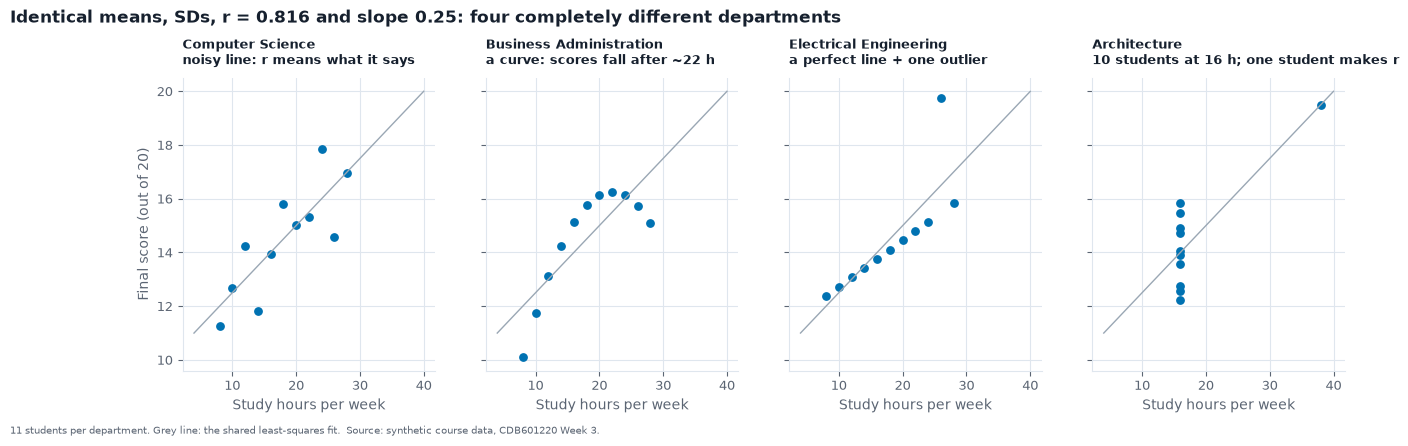

In [12]:
order = ["Computer Science", "Business Administration", "Electrical Engineering", "Architecture"]
notes = {"Computer Science": "noisy line: r means what it says",
         "Business Administration": "a curve: scores fall after ~22 h",
         "Electrical Engineering": "a perfect line + one outlier",
         "Architecture": "10 students at 16 h; one student makes r"}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharex=True, sharey=True)
xs = np.array([4, 40])
for ax, d in zip(axes, order):
    g = c4[c4.department == d]
    ax.scatter(g.study_hours_per_week, g.final_score_out_of_20, color=BLUE, s=28)
    ax.plot(xs, np.polyval(np.polyfit(g.study_hours_per_week, g.final_score_out_of_20, 1), xs), color=GREY, lw=1)
    ax.set_title(f"{d}\n{notes[d]}", fontsize=9)
    ax.set_xlabel("Study hours per week")
axes[0].set_ylabel("Final score (out of 20)")
fig.suptitle("Identical means, SDs, r = 0.816 and slope 0.25: four completely different departments",
             x=0.01, ha="left", fontweight="bold", y=1.06)
save(fig, "a4_anscombe_departments.png", "11 students per department. Grey line: the shared least-squares fit.")

**The redesign.** Plot them. Four small multiples on shared axes, each with the fitted line every one of
them "shares". Funding policy belongs to what each panel shows, not to the table.

---
## 5 · "Five cohorts, one set of statistics"

Recipe: the same table, one column per `shape_name`.

In [13]:
c5 = pd.read_csv(DATA / "case05_same_stats_shapes.csv")
summary_table(c5, "shape_name", "hours_on_platform", "assessment_score")

,ring,star,straight line,the letter X,two clusters
n,180.000,180.000,180.000,180.000,180.000
mean hours_on_platform,48.000,48.000,48.000,48.000,48.000
mean assessment_score,63.000,63.000,63.000,63.000,63.000
SD hours_on_platform,12.033,12.033,12.033,12.033,12.033
SD assessment_score,15.042,15.042,15.042,15.042,15.042
Pearson r,0.420,0.420,0.420,0.420,0.420
slope,0.525,0.525,0.525,0.525,0.525


**Self-check:** every cohort reports 48.00 / 63.00, SD 12.00 / 15.00, r = 0.420 (the brief rounds the
sample SD, 12.03 / 15.04 here). ✓

**The conclusion it invites.** The five cohorts used the platform the same way.

**The decoy.** "r = 0.42 is a moderate positive relationship in every cohort." In a *straight line* it
would be. The cohort named "straight line" isn't the only shape, and in the others r describes no
relationship that actually exists.

**The mechanism: the statistics were forced.** `vizlib.match_stats()` shifts and scales any point cloud
until it hits a target mean, SD and r, while keeping its shape. That's how Matejka & Fitzmaurice built the
Datasaurus. A ring, a star, an X, two clusters and a line all end up with the same five numbers, because
those numbers only measure centre, spread and *linear* association.

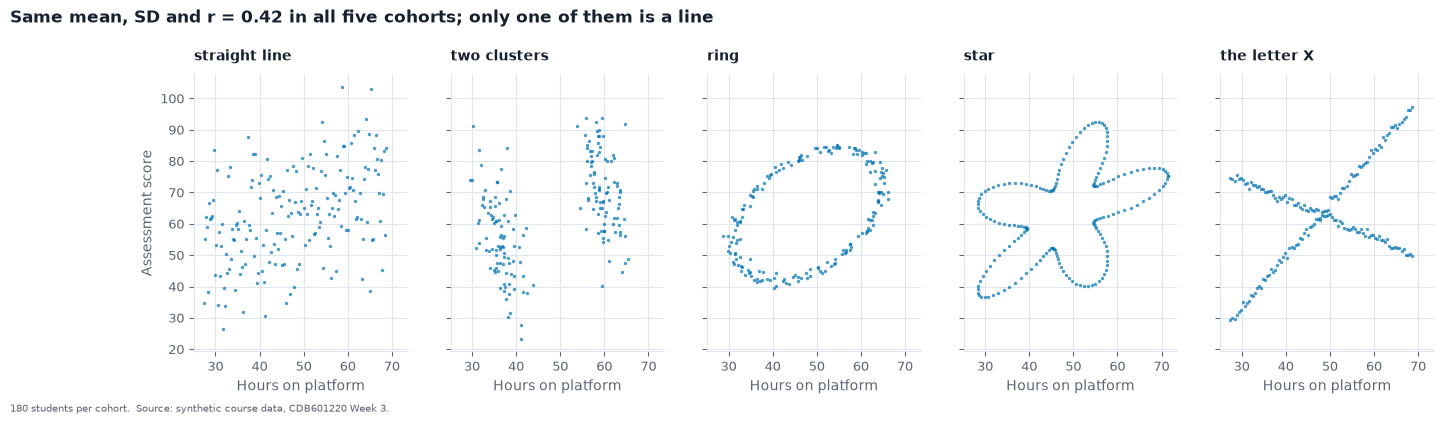

In [14]:
names = ["straight line", "two clusters", "ring", "star", "the letter X"]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6), sharex=True, sharey=True)
for ax, n in zip(axes, names):
    g = c5[c5.shape_name == n]
    ax.scatter(g.hours_on_platform, g.assessment_score, s=6, color=BLUE, alpha=0.7, lw=0)
    ax.set_title(n, fontsize=10)
    ax.set_xlabel("Hours on platform")
axes[0].set_ylabel("Assessment score")
fig.suptitle("Same mean, SD and r = 0.42 in all five cohorts; only one of them is a line",
             x=0.01, ha="left", fontweight="bold", y=1.06)
save(fig, "a5_same_stats_shapes.png", "180 students per cohort.")

**The redesign.** Again, plot it. The table should never travel without the scatter.

---
## 6 · "Creatinine tracks HbA1c — a finding"

Recipe: correlation matrix of the 20 numeric columns, drawn with `cmap="Reds"`, no `vmin`/`vmax`, both
triangles.

In [15]:
c6 = pd.read_csv(DATA / "case06_sensor_matrix.csv")
num = c6.drop(columns=["age_band", "study_site", "hr_device_model"])
corr = num.corr()
print(f"matrix {corr.shape[0]} x {corr.shape[1]}; creatinine-hba1c {corr.loc['creatinine', 'hba1c']:.2f}; "
      f"systolic-map {corr.loc['systolic', 'map_mmhg']:.2f}; lowest r {corr.min().min():.2f}")

matrix 20 x 20; creatinine-hba1c 0.77; systolic-map 0.96; lowest r -0.23


**Self-check:** creatinine ↔ HbA1c 0.77, systolic ↔ MAP 0.96, 20 × 20. ✓

**The conclusion it invites.** Kidney function and blood sugar move together, which is worth a paper.

**The decoy.** "It's confounded by age." `age_years` is in the matrix, and it correlates with neither
(−0.08 with creatinine, −0.07 with HbA1c). Age isn't the link.

In [16]:
z = (num[["creatinine", "hba1c"]] - num[["creatinine", "hba1c"]].drop(0).mean()) / num[["creatinine", "hba1c"]].drop(0).std()
print("participant 0:", c6.loc[0, ["study_site", "age_band", "creatinine", "hba1c"]].to_dict())
print(f"  that is {z.loc[0, 'creatinine']:.0f} SD above the other 179 on creatinine, {z.loc[0, 'hba1c']:.0f} SD on HbA1c")
print(f"r with all 180: {corr.loc['creatinine', 'hba1c']:+.3f}   without participant 0: "
      f"{num.drop(0).creatinine.corr(num.drop(0).hba1c):+.3f}   Spearman (rank) with all 180: "
      f"{num.creatinine.corr(num.hba1c, method='spearman'):+.3f}")
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().dropna()
r_crit = 0.1463   # two-sided p < .05 at n = 180
print(f"{len(pairs)} distinct pairs; {(pairs.abs() > r_crit).sum()} pass p < .05; about {0.05 * len(pairs):.1f} would by chance alone")

participant 0: {'study_site': 'Site C', 'age_band': '<30', 'creatinine': 1050.0, 'hba1c': 15.8}
  that is 86 SD above the other 179 on creatinine, 16 SD on HbA1c
r with all 180: +0.765   without participant 0: -0.004   Spearman (rank) with all 180: +0.032
190 distinct pairs; 20 pass p < .05; about 9.5 would by chance alone


**What it says: one participant is the "finding".** A single person (Site C, under 30) has creatinine
**1,050 µmol/L** and HbA1c **15.8%**, 86 and 16 SD beyond everyone else. Pearson r is a sum of products
of deviations, so one point that far out in both directions produces r = 0.77 by itself. Without that
participant r = **−0.004**, and the rank correlation with them included is **0.03**. It's a data-entry
error or one very sick patient, not a relationship. And with 190 pairs screened, about 9.5 would pass
p < .05 by chance alone, so a matrix is a place to look, not a result.

**How it's drawn (a separate problem).** `Reds` with no `vmin`/`vmax` stretches the colour scale from the
matrix's own minimum (−0.23) to 1. So **zero isn't neutral**, a negative correlation looks like "a bit
less red" instead of the opposite sign, and the 20 diagonal 1s plus the mirrored upper triangle spend most
of the ink on nothing. It also includes `map_mmhg`, which is *computed* from systolic and diastolic, so
its 0.96 and 0.97 are arithmetic, and six uncalibrated probe channels.

**Which fix solves which:** fixing the drawing (`RdBu_r`, −1 to +1, centred, lower triangle) makes the
signs and sizes readable. It does **nothing** about the creatinine claim, because that cell is still 0.77.
Only looking at the data (the scatter) fixes the finding.

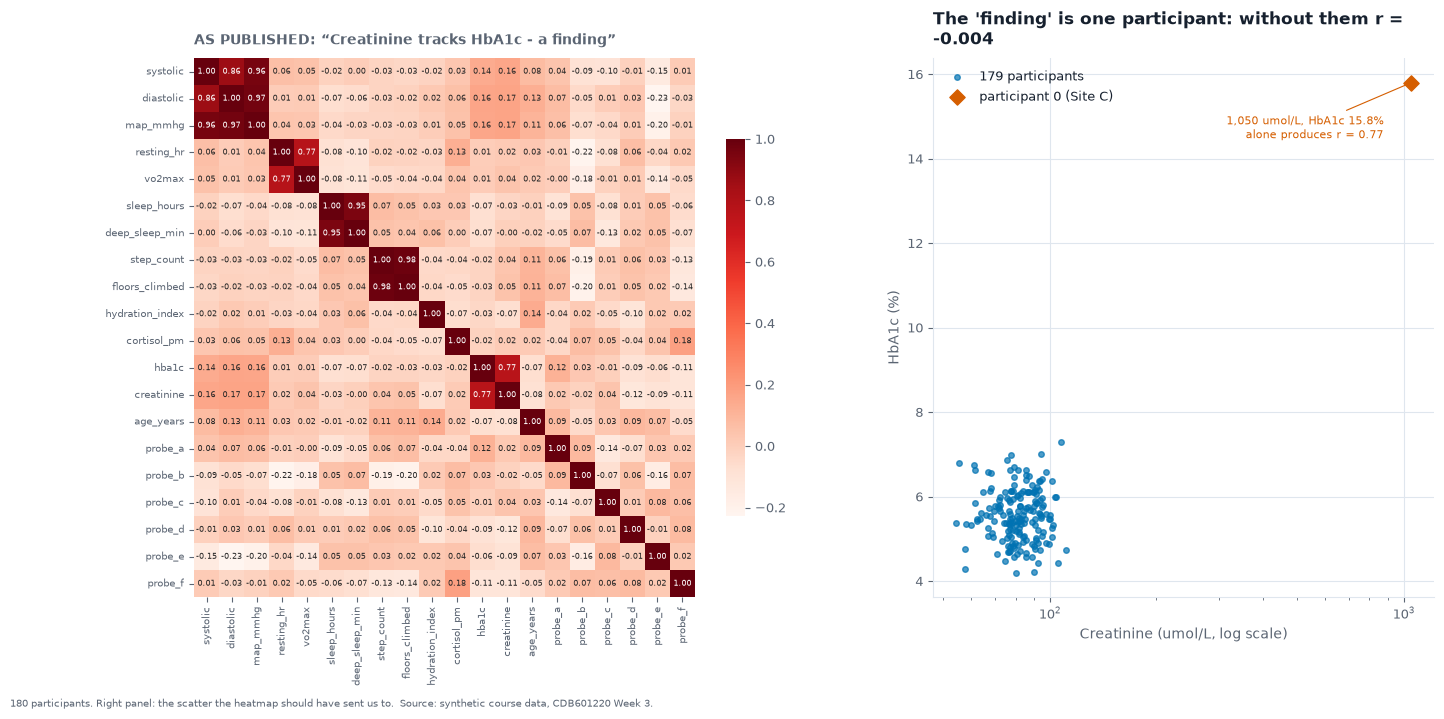

In [17]:
fig, (a, b) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw=dict(width_ratios=[1.25, 1]))
sns.heatmap(corr, cmap="Reds", annot=True, fmt=".2f", annot_kws=dict(size=5.5), ax=a, cbar_kws=dict(shrink=0.7))
a.tick_params(labelsize=7)
published(a, "Creatinine tracks HbA1c - a finding")

b.scatter(num.creatinine.drop(0), num.hba1c.drop(0), color=BLUE, s=16, alpha=0.7, label="179 participants")
b.scatter([num.creatinine[0]], [num.hba1c[0]], color=ORANGE, s=60, marker="D", label="participant 0 (Site C)")
b.set_xscale("log")
b.set_xlabel("Creatinine (umol/L, log scale)")
b.set_ylabel("HbA1c (%)")
b.legend(loc="upper left")
b.annotate("1,050 umol/L, HbA1c 15.8%\nalone produces r = 0.77", (num.creatinine[0], num.hba1c[0]),
           xytext=(-20, -40), textcoords="offset points", ha="right", fontsize=8, color=ORANGE,
           arrowprops=dict(arrowstyle="-", color=ORANGE, lw=0.8))
b.set_title(wrap("The 'finding' is one participant: without them r = -0.004"))
save(fig, "a6_one_point_correlation.png", "180 participants. Right panel: the scatter the heatmap should have sent us to.")

**The redesign.** Use the heatmap as a screen, then plot the pair it flags. The scatter shows one point
and a shapeless cloud. (Part D builds the heatmap itself to the Lecture 6 rules.)

---
## 7 · "ShaheenGo ran at a loss until May"

Recipe: two y-axes, revenue on the left from 50 to 80, cost on the right from 40 to 56.

In [18]:
c7 = pd.read_csv(DATA / "case07_dual_axis_series.csv")
c7["margin"] = c7.revenue_pkr_m - c7.cost_pkr_m
print(c7.to_string(index=False))

month  revenue_pkr_m  cost_pkr_m  margin
  Jan             52          44       8
  Feb             58          46      12
  Mar             61          47      14
  Apr             66          49      17
  May             71          51      20
  Jun             78          53      25


**Self-check:** the cost line sits above the revenue line for Jan–Apr. ✓

**The conclusion it invites.** Costs exceeded revenue until May, so the company was losing money.

**The decoy.** "The two series are in different units, so the axes needed separate scales." They aren't.
Both are PKR millions, the same unit, so one axis was always possible.

**The mechanism: the crossing is made by the two axis ranges.** On a twin axis, where a line sits depends
on the limits chosen for *its own* axis. Revenue's 50–80 and cost's 40–56 were picked separately, so the
"crossover" in May is where two arbitrary rulers happen to line up. The table says revenue was above cost
**in every month**: the margin was 8, 12, 14, 17, 20, 25. The company was in profit the whole time, and
the margin tripled.

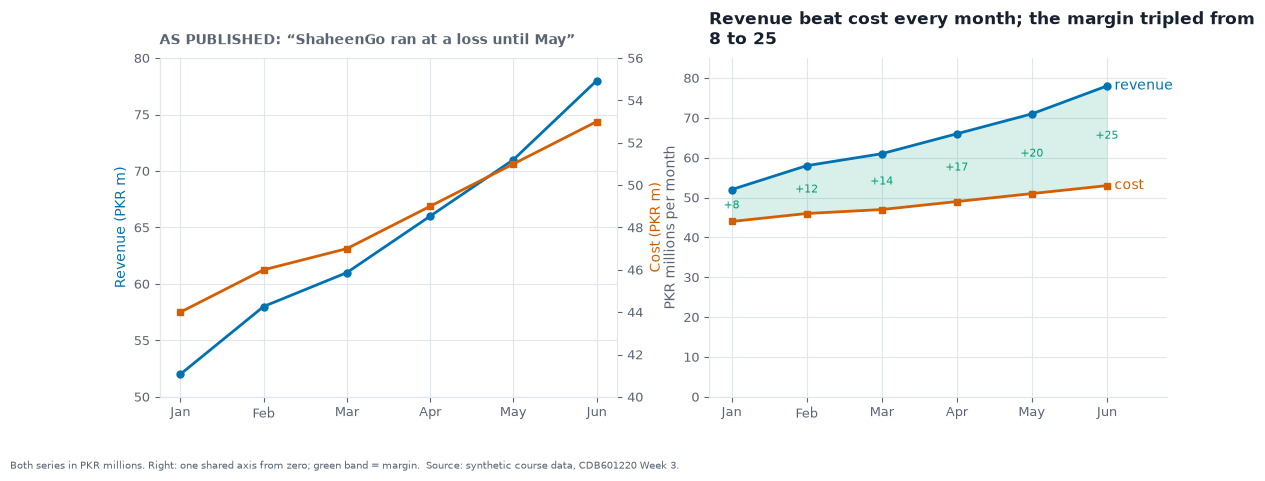

In [19]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.4))
a.plot(c7.month, c7.revenue_pkr_m, color=BLUE, marker="o")
a.set_ylim(50, 80)
a.set_ylabel("Revenue (PKR m)", color=BLUE)
a2 = a.twinx()
a2.plot(c7.month, c7.cost_pkr_m, color=ORANGE, marker="s")
a2.set_ylim(40, 56)
a2.set_ylabel("Cost (PKR m)", color=ORANGE)
a2.spines["right"].set_visible(True)
a2.grid(False)
published(a, "ShaheenGo ran at a loss until May")

b.plot(c7.month, c7.revenue_pkr_m, color=BLUE, marker="o")
b.plot(c7.month, c7.cost_pkr_m, color=ORANGE, marker="s")
b.fill_between(range(6), c7.cost_pkr_m, c7.revenue_pkr_m, color=GREEN, alpha=0.15, lw=0)
b.text(5.1, c7.revenue_pkr_m.iloc[-1], "revenue", color=BLUE, va="center")
b.text(5.1, c7.cost_pkr_m.iloc[-1], "cost", color=ORANGE, va="center")
for i, m in enumerate(c7.margin):
    b.text(i, (c7.revenue_pkr_m[i] + c7.cost_pkr_m[i]) / 2, f"+{m}", ha="center", va="center", fontsize=8, color=GREEN)
b.set_xlim(-0.3, 5.8)
b.set_ylim(0, 85)
b.set_ylabel("PKR millions per month")
b.set_title(wrap("Revenue beat cost every month; the margin tripled from 8 to 25"))
save(fig, "a7_dual_axis.png", "Both series in PKR millions. Right: one shared axis from zero; green band = margin.")

**The redesign.** One axis, because one unit, and from zero, with the margin shaded and labelled. Part B
question 5 explains why this chart can't even be given a Lie Factor.

---
## 8 · "Three bin widths, three different distributions"

Recipe: three histograms of `systolic`, `bins=3`, `bins=45`, `bins=400`.

In [20]:
vt = pd.read_csv(DATA / "vitals_10k.csv")
sy = vt.systolic
print(f"n = {sy.notna().sum():,}; {sy.nunique()} distinct values ({sy.min()} to {sy.max()}, whole mmHg only)")
for k in (3, 45, 400):
    h, e = np.histogram(sy, bins=k)
    print(f"bins={k:3d}: bin width {e[1] - e[0]:5.2f} mmHg, empty bins {(h == 0).sum():3d} of {k}")

n = 10,000; 104 distinct values (92 to 199, whole mmHg only)
bins=  3: bin width 35.67 mmHg, empty bins   0 of 3
bins= 45: bin width  2.38 mmHg, empty bins   0 of 45
bins=400: bin width  0.27 mmHg, empty bins 296 of 400


**Self-check:** n = 10,000 in all three panels. ✓

**The conclusion it invites.** The shape of a distribution is in the eye of the analyst, since the same
data can look like anything.

**The decoy.** "The three panels use different data." They don't. It's the same 10,000 values, so every
difference is a drawing decision.

**The mechanism: two different bin-width failures, on integer data.**

- **`bins=3`** makes bins 35.7 mmHg wide and averages away the shape. It shows a falling staircase and
  hides that the data have **two peaks**.
- **`bins=400`** makes bins 0.27 mmHg wide, but systolic is recorded in **whole mmHg** (104 distinct
  values). So 296 of the 400 bins *can't* contain anything. That's a picket fence of gaps that aren't in
  the data.
- **`bins=45`** (2.4 mmHg) is close to sensible, and it shows two populations: about 60% around 120 and
  about 40% around 165.

The right bin width is a whole number of mmHg with edges on half-values, so every bin holds the same
number of possible readings.

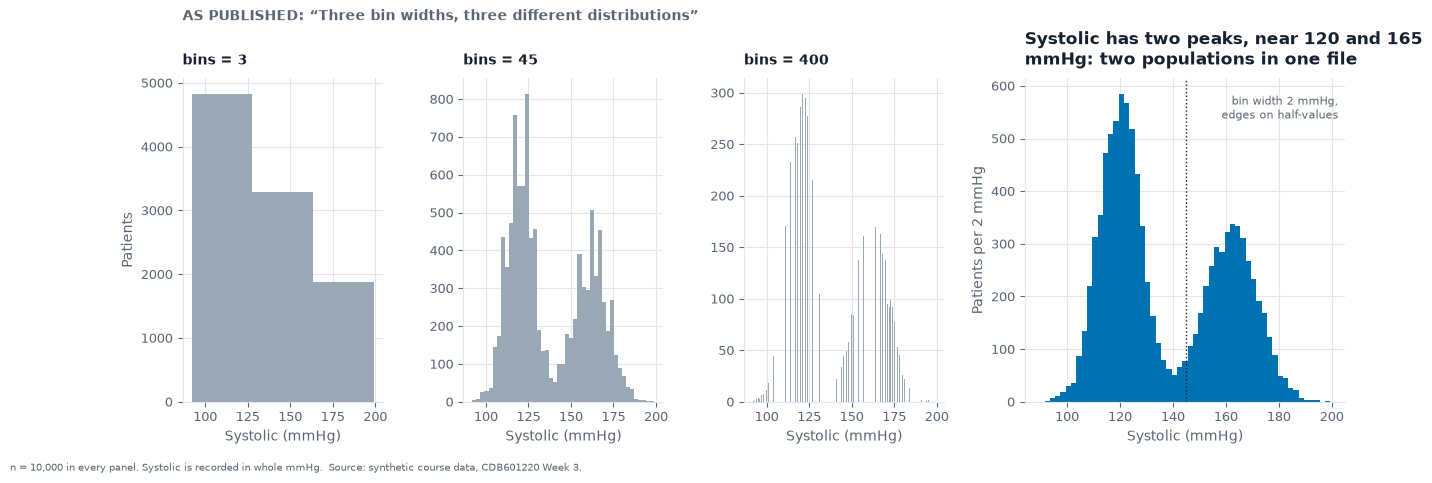

In [21]:
fig = plt.figure(figsize=(15, 4.2))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 1.6], wspace=0.35)
for i, k in enumerate((3, 45, 400)):
    ax = fig.add_subplot(gs[i])
    ax.hist(sy, bins=k, color=GREY)
    ax.set_title(f"bins = {k}", fontsize=10)
    ax.set_xlabel("Systolic (mmHg)")
    if i == 0:
        ax.set_ylabel("Patients")
        ax.text(0, 1.18, "AS PUBLISHED: “Three bin widths, three different distributions”",
                transform=ax.transAxes, fontsize=10, color=SOFT, fontweight="bold")
ax = fig.add_subplot(gs[3])
ax.hist(sy, bins=np.arange(89.5, 201.5, 2), color=BLUE)
ax.axvline(145, color=INK, ls=":", lw=1)
ax.set_xlabel("Systolic (mmHg)")
ax.set_ylabel("Patients per 2 mmHg")
ax.set_title(wrap("Systolic has two peaks, near 120 and 165 mmHg: two populations in one file", 45))
ax.text(0.98, 0.95, "bin width 2 mmHg,\nedges on half-values", transform=ax.transAxes, ha="right", va="top",
        fontsize=8, color=SOFT)
save(fig, "a8_bin_width.png", "n = 10,000 in every panel. Systolic is recorded in whole mmHg.")

**The redesign.** One histogram with a stated bin width (2 mmHg) aligned to the integer data, and the
bimodality named in the title. Part D asks what separates the two groups.

---
## 9 · "4.4% of the density sits above 100% saturation"

Recipe: a KDE of `spo2` with the default bandwidth, x-axis extended to 108, and 100 marked.

In [22]:
sp = vt.spo2
print(f"max SpO2 in the data: {sp.max()}; readings at exactly 100: {(sp == 100).sum()} ({(sp == 100).mean():.1%}); "
      f"at 99 or 100: {(sp >= 99).mean():.1%}")
bw = sp.std() * len(sp) ** (-1 / 5)       # Scott's rule, seaborn's default
above = norm.sf((100 - sp.to_numpy(float)) / bw).mean()
print(f"default (Scott) bandwidth {bw:.2f} pt: {above:.2%} of the density above 100")
for b_ in (0.5, 0.93, 1.5):
    print(f"   bandwidth {b_:.2f}: {norm.sf((100 - sp.to_numpy(float)) / b_).mean():.2%} above 100")

max SpO2 in the data: 100; readings at exactly 100: 304 (3.0%); at 99 or 100: 21.4%
default (Scott) bandwidth 0.35 pt: 1.56% of the density above 100
   bandwidth 0.50: 1.94% above 100
   bandwidth 0.93: 4.48% above 100
   bandwidth 1.50: 8.71% above 100


**Self-check:** the maximum value is 100, and the curve isn't. ✓ (I measure **1.6%** of the density above
100 with seaborn's current default, Scott's rule with a bandwidth of 0.35 points. The brief's 4.4%
corresponds to a bandwidth of about 0.93. The size depends on the bandwidth, but there is spill at any
bandwidth, which is the point.)

**The conclusion it invites.** Some patients are above 100% saturated, or the oximeters over-read.

**The decoy.** "There are bad readings above 100." The maximum in the file is exactly 100. There isn't
one reading above it.

**The mechanism: a kernel ignores physical limits.** A KDE puts a small Gaussian on every reading,
and a Gaussian has tails on both sides. 304 readings sit exactly at the ceiling of 100, and 21% sit at 99
or 100, so half of each of their kernels lands on impossible values. The curve above 100 isn't in the
data. It's the shape of the kernel. SpO2 is also an integer, so a smooth curve invents values *between*
97 and 98 that the oximeter can't report.

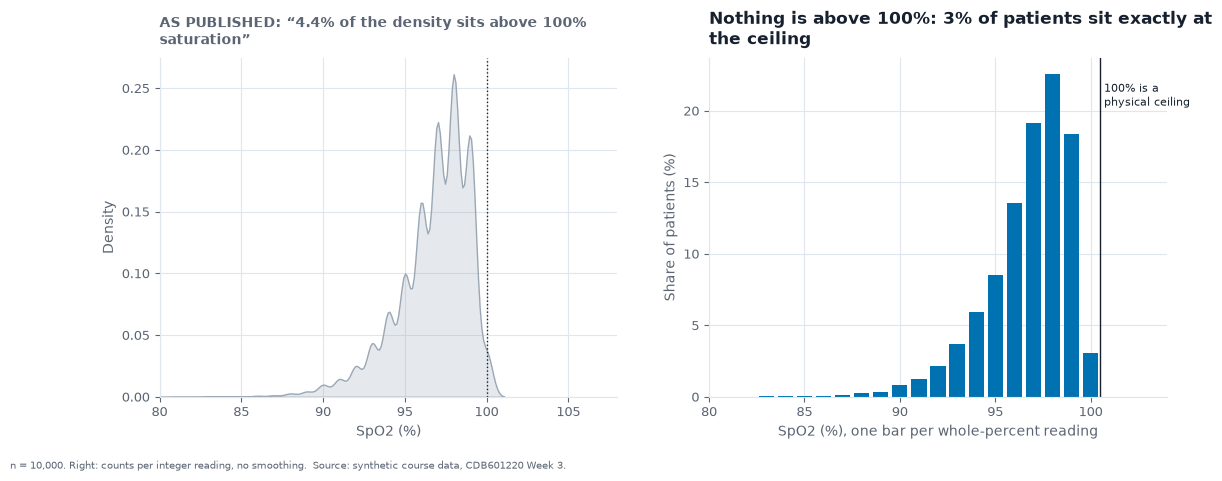

In [23]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.4))
sns.kdeplot(x=sp, ax=a, color=GREY, fill=True)
a.axvline(100, color=INK, ls=":", lw=1)
a.set_xlim(80, 108)
a.set_xlabel("SpO2 (%)")
published(a, "4.4% of the density sits above 100% saturation")

cnt = sp.value_counts().sort_index()
b.bar(cnt.index, cnt.values / len(sp) * 100, width=0.8, color=BLUE)
b.axvline(100.5, color=INK, lw=1)
b.text(100.7, 22, "100% is a\nphysical ceiling", fontsize=8, va="top")
b.set_xlim(80, 104)
b.set_xlabel("SpO2 (%), one bar per whole-percent reading")
b.set_ylabel("Share of patients (%)")
b.set_title(wrap("Nothing is above 100%: 3% of patients sit exactly at the ceiling"))
save(fig, "a9_kde_ceiling.png", "n = 10,000. Right: counts per integer reading, no smoothing.")

**The redesign.** For a bounded integer measure, one bar per possible reading, with the ceiling drawn.
If a smooth curve is required, `cut=0` or `clip=(None, 100)` stops it at the boundary, and the bandwidth
goes in the caption.

---
## Summary

| # | Claim | Mechanism | The number |
|---|---|---|---|
| 1 | Premium helmets 2.5× worse | Simpson's paradox: road type confounds | Premium lower on all 3 roads; 85% of its trips on motorways |
| 2 | Chai predicts failures | Enrolment drives both counts | r 0.98 → 0.29 per student |
| 3 | AQI cut by a third | 9 dirtiest stations went offline | 13 constant stations: 137.1 → 137.2 |
| 4 | Departments identical | Anscombe's quartet | Same 5 statistics, 4 different shapes |
| 5 | Cohorts identical | Statistics forced by `match_stats` | Same 5 statistics, 5 shapes |
| 6 | Creatinine tracks HbA1c | One extreme participant | r 0.77 → −0.004 without them |
| 7 | Loss until May | Dual axes with independent limits | Margin +8 to +25, positive every month |
| 8 | Bin width changes the shape | Coarse bins hide bimodality; fine bins on integers make gaps | 296 of 400 bins empty |
| 9 | Density above 100% | Kernel tails cross a physical ceiling | Max reading 100; 304 at the ceiling |